# BDC Pitch: follow-up tests

`eda.ipynb` found that a deep discount predicts NAV cuts, but not returns. Two follow-ups:

1. **Earnings-day test.** If the market already expects the NAV cut, the share price should react only to the
   *unexpected* part of the NAV change on the day results come out. If it also reacts to the part the discount
   already predicted, the market is slow, and that is a trade (e.g. short deep-discount BDCs into earnings).
2. **Dropout test.** In `eda.ipynb`, when a BDC marked a stressed loan above its peers, the peers moved up toward it
   next quarter. But a loan that defaults is often restructured or written off and disappears from the schedules, so
   the pairs we could follow may be the ones that recovered. Track every pair, including the ones that disappear,
   and bound the answer.

## 1. Data

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from borrowers import assign

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
DATA = Path("data")
LAG_DAYS = 95

uni = pd.read_csv(DATA / "universe.csv")
listed = set(uni.loc[uni.listed, "ticker"])
nav = pd.read_csv(DATA / "bdc_nav.csv", parse_dates=["period_end", "filed"])
nav = nav[nav.period_end.dt.is_quarter_end & nav.nav_ps.gt(0)]
nav = nav[(nav.filed - nav.period_end).dt.days <= LAG_DAYS]
nav = nav.sort_values(["ticker", "period_end"]).drop_duplicates(["ticker", "period_end"])
nav = nav[nav.period_end >= "2022-03-31"]
nv = nav.pivot(index="period_end", columns="ticker", values="nav_ps")
filed10q = nav.pivot(index="period_end", columns="ticker", values="filed")
qs = list(nv.index)

px = pd.read_csv(DATA / "prices.csv", parse_dates=["date"])
close = px.pivot(index="date", columns="ticker", values="close")
adj = px.pivot(index="date", columns="ticker", values="adj_close")
cal = close.index

ek = pd.read_csv(DATA / "earnings_8k.csv")
# EDGAR acceptance times are UTC; convert to New York time
ek["ts"] = pd.to_datetime(ek.accepted, utc=True).dt.tz_convert("America/New_York").dt.tz_localize(None)
print(f"8-K Item 2.02 filings: {len(ek)}, listed BDCs with any: {ek.ticker.isin(listed).sum() and ek[ek.ticker.isin(listed)].ticker.nunique()}")

8-K Item 2.02 filings: 962, listed BDCs with any: 42


## 2. Earnings-day test
**Event.** For BDC i and quarter q, the announcement is the first 8-K Item 2.02 (results) after the quarter ends and
no later than the day after the 10-Q is filed; if there is none, the 10-Q filing date. Day 0 is the first trading
day whose close comes after the announcement (anything after 4pm counts for the next day).

**Measures.**
* `ar`: abnormal return = BDC total return minus BIZD (BDC ETF) total return, close of day −1 to close of day +1.
* `disc_pre`: price on day −2 / previous quarter's NAV − 1 (everything known before the event).
* `dnav`: NAV_q / NAV_{q−1} − 1, the news.
* `pred`: expected NAV change, from a cross-sectional regression of `dnav` on `disc_pre` fitted only on earlier
  quarters (expanding window). `surprise` = `dnav` − `pred`.

All four are demeaned within each quarter so a market-wide move does not drive results.

In [2]:
def day0(ts):
    d = ts.normalize()
    if ts.hour >= 16:
        d += pd.Timedelta(days=1)
    i = cal.searchsorted(d)
    return i if i < len(cal) else None

ev = []
for t in sorted(set(nv.columns) & listed & set(adj.columns)):
    e = ek[ek.ticker == t].sort_values("ts")
    for k in range(1, len(qs)):
        q, qp = qs[k], qs[k - 1]
        if pd.isna(nv.at[q, t]) or pd.isna(nv.at[qp, t]):
            continue
        f = filed10q.at[q, t]
        cand = e[(e.ts > q + pd.Timedelta(days=7)) & (e.ts <= f + pd.Timedelta(days=1, hours=23))]
        if len(cand):
            i0, src = day0(cand.ts.iloc[0]), "8-K"
        else:
            i0, src = cal.searchsorted(f), "10-Q"
        if i0 is None or i0 < 2 or i0 + 1 >= len(cal):
            continue
        a, b = adj[t], adj["BIZD"]
        dm1, dp1 = cal[i0 - 1], cal[i0 + 1]
        r_i = a.asof(dp1) / a.asof(dm1) - 1
        r_m = b.asof(dp1) / b.asof(dm1) - 1
        ev.append({"ticker": t, "q": q, "day0": cal[i0], "src": src, "ar": r_i - r_m,
                   "disc_pre": close[t].asof(cal[i0 - 2]) / nv.at[qp, t] - 1,
                   "dnav": nv.at[q, t] / nv.at[qp, t] - 1})
E = pd.DataFrame(ev).dropna()
for c in ["ar", "disc_pre", "dnav"]:
    E["cs_" + c] = E[c] - E.groupby("q")[c].transform("median")

# expected NAV change from the pre-event discount, coefficients from earlier quarters only
E["pred"] = np.nan
for q in sorted(E.q.unique()):
    past = E[E.q < q]
    if past.q.nunique() < 3:
        continue
    b = sm.OLS(past.cs_dnav, sm.add_constant(past.cs_disc_pre)).fit().params
    m = E.q == q
    E.loc[m, "pred"] = b["const"] + b["cs_disc_pre"] * E.loc[m, "cs_disc_pre"]
E["surprise"] = E.cs_dnav - E.pred
print(E.src.value_counts().to_string())
print(f"events {len(E)}, with expanding prediction {E.pred.notna().sum()}; BDCs {E.ticker.nunique()}, quarters {E.q.nunique()}")
print(f"abnormal return: mean {E.ar.mean():+.2%}, sd {E.ar.std():.2%}")

src
8-K     548
10-Q     41
events 589, with expanding prediction 519; BDCs 41, quarters 16
abnormal return: mean -0.20%, sd 4.21%


**Test 2a: does the price react to NAV news at all?** (sanity check: it should)

**Test 2b: does it react to the predictable part?** Regress `ar` on `pred` and `surprise`. If the discount already
priced the NAV change, the slope on `pred` is about 0 and the slope on `surprise` is positive.

In [3]:
cl = lambda d: {"groups": d.q.astype("int64")}
f1 = sm.OLS(E.cs_ar, sm.add_constant(E.cs_dnav)).fit(cov_type="cluster", cov_kwds=cl(E))
print("2a  ar ~ NAV change:")
print(f1.summary().tables[1])
D = E.dropna(subset=["pred"])
f2 = sm.OLS(D.cs_ar, sm.add_constant(D[["pred", "surprise"]])).fit(cov_type="cluster", cov_kwds=cl(D))
print("\n2b  ar ~ predicted part + surprise:")
print(f2.summary().tables[1])
f3 = sm.OLS(E.cs_ar, sm.add_constant(E[["cs_disc_pre", "cs_dnav"]])).fit(cov_type="cluster", cov_kwds=cl(E))
print("\n2c  ar ~ pre-event discount + NAV change:")
print(f3.summary().tables[1])

2a  ar ~ NAV change:
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0023      0.002     -1.216      0.224      -0.006       0.001
cs_dnav        0.1628      0.099      1.652      0.099      -0.030       0.356

2b  ar ~ predicted part + surprise:
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0039      0.002     -1.936      0.053      -0.008     4.8e-05
pred          -0.1161      0.144     -0.804      0.422      -0.399       0.167
surprise       0.1785      0.113      1.576      0.115      -0.043       0.401

2c  ar ~ pre-event discount + NAV change:
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const          -0.0010      

**Test 2d: a tradable version.** Sort on the pre-event discount only (known before the event). If deep-discount BDCs
fall on earnings day relative to the rest, shorting them into earnings is a trade.

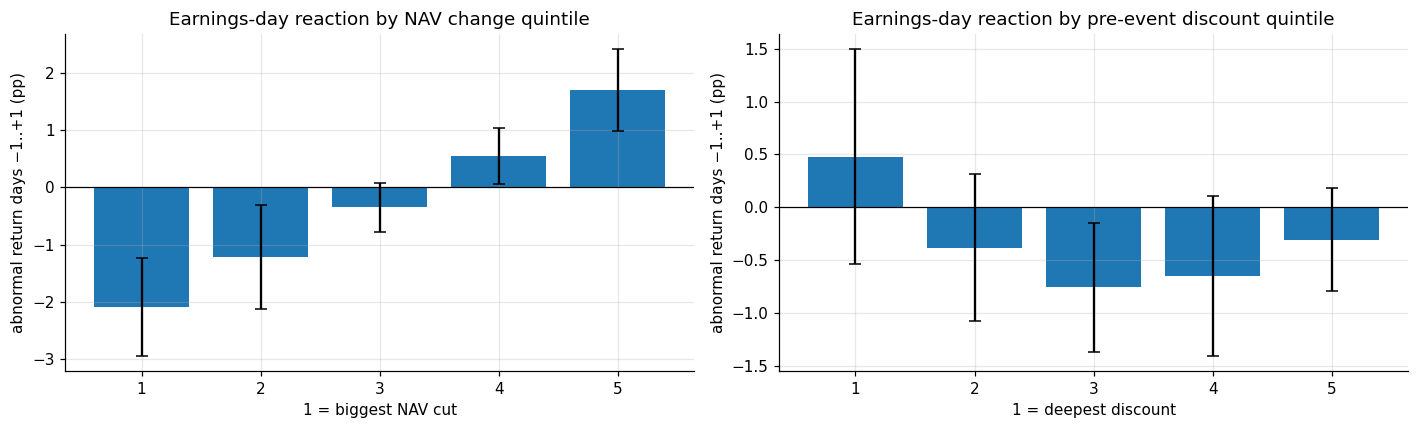

surp_q: Kruskal H=64.32 p=0.0000 | Q1 -2.08% vs Q5 +1.69%, Welch t=-6.64 p=0.0000, n=588


disc_q: Kruskal H=5.91 p=0.2058 | Q1 +0.48% vs Q5 -0.31%, Welch t=+1.37 p=0.1736, n=588

per-quarter Q5−Q1 earnings-window spread: mean -0.79%, t=-1.24, hit 33% of 15 quarters


In [4]:
qb = lambda x: pd.qcut(x.rank(method="first"), 5, labels=False) + 1 if x.notna().sum() >= 10 else pd.Series(np.nan, index=x.index)
E["disc_q"] = E.groupby("q").cs_disc_pre.transform(qb)
E["surp_q"] = E.groupby("q").cs_dnav.transform(qb)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, col, ttl in [(ax[0], "surp_q", "Earnings-day reaction by NAV change quintile"),
                    (ax[1], "disc_q", "Earnings-day reaction by pre-event discount quintile")]:
    g = E.dropna(subset=[col]).groupby(col).cs_ar
    a.bar(g.mean().index, g.mean() * 100, yerr=g.sem() * 196, capsize=4)
    a.axhline(0, c="k", lw=0.8); a.set_title(ttl); a.set_ylabel("abnormal return days −1..+1 (pp)")
ax[0].set_xlabel("1 = biggest NAV cut"); ax[1].set_xlabel("1 = deepest discount")
plt.tight_layout(); plt.show()
for col in ["surp_q", "disc_q"]:
    d = E.dropna(subset=[col]); g = [x.cs_ar.values for _, x in d.groupby(col)]
    H, p = stats.kruskal(*g); q1, q5 = d[d[col] == 1].cs_ar, d[d[col] == 5].cs_ar
    t, pt = stats.ttest_ind(q1, q5, equal_var=False)
    print(f"{col}: Kruskal H={H:.2f} p={p:.4f} | Q1 {q1.mean():+.2%} vs Q5 {q5.mean():+.2%}, Welch t={t:+.2f} p={pt:.4f}, n={len(d)}")

# short Q1 / long Q5 by pre-event discount each quarter, through the 3-day window
r = E.dropna(subset=["disc_q"]).groupby("q").apply(lambda g: g[g.disc_q == 5].ar.mean() - g[g.disc_q == 1].ar.mean())
print(f"\nper-quarter Q5−Q1 earnings-window spread: mean {r.mean():+.2%}, t={r.mean() / r.std() * np.sqrt(len(r)):+.2f}, "
      f"hit {(r > 0).mean():.0%} of {len(r)} quarters")

## 3. Dropout test
**Setup.** Same loan matching as `eda.ipynb`: loan = borrower + spread rounded to 0.25%; mark = fair value / principal;
peer mark = median of the other BDCs holding that loan (needs ≥ 2). Focus on **stressed loans** (peer mark < 90) where a
BDC disagrees with peers by **more than 5 points**: the cases that drove the earlier result.

**What happens next quarter.** For each such case:
* **both seen:** the BDC and at least one peer still hold the loan (the only cases the earlier test used);
* **peers only / BDC only:** one side exited;
* **gone:** nobody holds the loan at the same spread. Before giving up, look for the same *borrower* at any spread
  (restructured loans are often re-papered with new terms).

**Who was right?** "Truth" = the next-quarter mark of the other BDCs (or of anyone still holding the borrower). Compare
how far the BDC's mark and the peer mark were from the truth. For loans that vanish, compute two bounds: truth = the
lower of the two marks (the optimist was wrong) and truth = the higher (the optimist was right).

In [5]:
pos = pd.read_csv(DATA / "bdc_positions.csv.gz", parse_dates=["period_end", "filed"], low_memory=False)
pos = pos[pos.identifier.notna() & pos.principal.gt(0) & pos.fv.notna()]
pos = pos[~pos.identifier.str.contains(r"revolv|delayed|ddtl|\bdelay|unfunded", case=False, regex=True)]
pos["mark"] = pos.fv / pos.principal
pos = pos[pos.mark.between(0.02, 1.15) & pos.principal.ge(1e6)]
pos["name"], _ = assign(pos)
pos["spread_n"] = np.where(pos.spread > 0.5, pos.spread / 100, pos.spread)
pos = pos[pos.name.notna()]
pos["loan"] = pos.name + " @" + (np.round(pos.spread_n * 400) / 4).map(lambda x: f"{x:.2f}" if pd.notna(x) else "na")

def wmark(df, keys):
    g = df.assign(w=df.mark * df.principal).groupby(keys).agg(w=("w", "sum"), p=("principal", "sum")).reset_index()
    g["mark"] = g.w / g.p
    return g.drop(columns=["w", "p"])
L = wmark(pos[pos.spread_n.between(0.005, 0.2)], ["ticker", "period_end", "loan"])
L["name"] = L.loan.str.rsplit(" @", n=1).str[0]
N = wmark(pos, ["ticker", "period_end", "name"])          # borrower level, any spread (follows restructurings)

L["n"] = L.groupby(["period_end", "loan"]).ticker.transform("count")
S = L[L.n >= 3].copy()
S["peer"] = S.groupby(["period_end", "loan"]).mark.transform(lambda m: pd.Series(
    [np.median(np.delete(m.values, i)) for i in range(len(m))], index=m.index))
S["gap"] = S.mark - S.peer
qlist = sorted(L.period_end.unique()); nxt = dict(zip(qlist[:-1], qlist[1:]))
C = S[(S.peer < 0.9) & (S.gap.abs() > 0.05) & S.period_end.isin(nxt)].copy()
C["q1"] = C.period_end.map(nxt)
print(f"stressed loans with a >5pt disagreement: {len(C)} (BDC above peers: {(C.gap > 0).sum()}, below: {(C.gap < 0).sum()})")

stressed loans with a >5pt disagreement: 464 (BDC above peers: 346, below: 118)


In [6]:
Lk = L.set_index(["period_end", "loan"]).sort_index()
Nk = N.set_index(["period_end", "name"]).sort_index()
def nxt_state(r):
    own1 = peer1 = np.nan; src = None
    if (r.q1, r.loan) in Lk.index:
        g = Lk.loc[(r.q1, r.loan)]
        o, p = g[g.ticker == r.ticker], g[g.ticker != r.ticker]
        own1 = o.mark.iloc[0] if len(o) else np.nan
        peer1 = p.mark.median() if len(p) else np.nan
    if np.isnan(own1) and (r.q1, r.name) in Nk.index:          # BDC re-papered the loan at a new spread
        g = Nk.loc[(r.q1, r.name)]; o = g[g.ticker == r.ticker]
        own1 = o.mark.iloc[0] if len(o) else np.nan
    if np.isnan(peer1) and (r.q1, r.name) in Nk.index:
        g = Nk.loc[(r.q1, r.name)]; p = g[g.ticker != r.ticker]
        peer1 = p.mark.median() if len(p) else np.nan
    state = ("both seen" if not np.isnan(own1) and not np.isnan(peer1) else "peers only" if not np.isnan(peer1)
             else "BDC only" if not np.isnan(own1) else "gone")
    return pd.Series({"own1": own1, "peer1": peer1, "state": state})
C = C.join(C.apply(nxt_state, axis=1))
C["side"] = np.where(C.gap > 0, "BDC above peers", "BDC below peers")
tab = pd.crosstab(C.side, C.state, normalize="index").mul(100).round(1)
tab["n"] = C.side.value_counts()
print("next-quarter status (% of cases):"); print(tab.to_string())

next-quarter status (% of cases):
state            BDC only  both seen  gone  peers only    n
side                                                       
BDC above peers       1.2       78.3  12.1         8.4  346
BDC below peers       0.8       74.6  13.6        11.0  118


In [7]:
# who was closer to the truth? truth = other BDCs' next-quarter mark; if they are gone, the BDC's own next mark
C["truth"] = C.peer1.fillna(C.own1)
hi, lo = np.maximum(C.mark, C.peer), np.minimum(C.mark, C.peer)
res = []
for scen, fill in [("observed only", None), ("vanished = lower mark (optimist wrong)", lo),
                   ("vanished = higher mark (optimist right)", hi)]:
    tr = C.truth if fill is None else C.truth.fillna(fill)
    d = C.assign(tr=tr).dropna(subset=["tr"])
    err_own, err_peer = (d.mark - d.tr).abs(), (d.peer - d.tr).abs()
    # "higher mark was closer": the optimistic side won
    high_is_own = d.gap > 0
    err_high = np.where(high_is_own, err_own, err_peer); err_low = np.where(high_is_own, err_peer, err_own)
    w = (err_high < err_low).mean()
    t = stats.ttest_1samp(err_low - err_high, 0)
    res.append({"scenario": scen, "n": len(d), "higher mark closer": f"{w:.0%}",
                "mean err higher (pt)": err_high.mean() * 100, "mean err lower (pt)": err_low.mean() * 100,
                "t (err_low − err_high)": t.statistic})
print(pd.DataFrame(res).round(2).to_string(index=False))

# same question two quarters out, observed cases only
C["q2"] = C.q1.map(nxt)
def peer2(r):
    if pd.isna(r.q2): return np.nan
    for key, idx, col in [((r.q2, r.loan), Lk, "ticker"), ((r.q2, r.name), Nk, "ticker")]:
        if key in idx.index:
            g = idx.loc[key]; p = g[g.ticker != r.ticker]
            if len(p): return p.mark.median()
    return np.nan
C["truth2"] = C.apply(peer2, axis=1)
d = C.dropna(subset=["truth2"])
eh = np.where(d.gap > 0, (d.mark - d.truth2).abs(), (d.peer - d.truth2).abs())
el = np.where(d.gap > 0, (d.peer - d.truth2).abs(), (d.mark - d.truth2).abs())
print(f"\ntwo quarters out (observed, n={len(d)}): higher mark closer {np.mean(eh < el):.0%}, "
      f"mean err higher {eh.mean() * 100:.2f}pt vs lower {el.mean() * 100:.2f}pt, t={stats.ttest_1samp(el - eh, 0).statistic:+.2f}")

                               scenario   n higher mark closer  mean err higher (pt)  mean err lower (pt)  t (err_low − err_high)
                          observed only 406                40%                 13.95                11.46                   -2.52
 vanished = lower mark (optimist wrong) 464                35%                 14.39                10.03                   -4.80
vanished = higher mark (optimist right) 464                48%                 12.21                12.22                    0.02

two quarters out (observed, n=333): higher mark closer 50%, mean err higher 12.68pt vs lower 15.07pt, t=+2.27


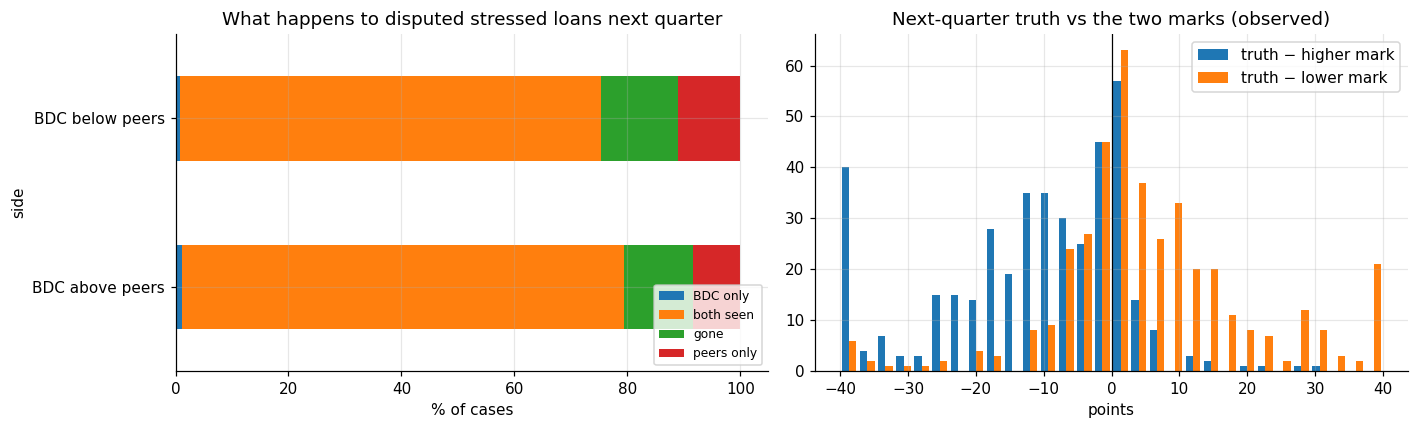

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
tab.drop(columns="n").plot.barh(stacked=True, ax=ax[0]); ax[0].set_xlabel("% of cases"); ax[0].set_title("What happens to disputed stressed loans next quarter")
ax[0].legend(fontsize=8, loc="lower right")
d = C.dropna(subset=["truth"]).copy()
d["hi_chg"] = np.where(d.gap > 0, d.truth - d.mark, d.truth - d.peer) * 100
d["lo_chg"] = np.where(d.gap > 0, d.truth - d.peer, d.truth - d.mark) * 100
ax[1].hist([d.hi_chg.clip(-40, 40), d.lo_chg.clip(-40, 40)], bins=30, label=["truth − higher mark", "truth − lower mark"])
ax[1].axvline(0, c="k", lw=0.8); ax[1].legend(); ax[1].set_xlabel("points"); ax[1].set_title("Next-quarter truth vs the two marks (observed)")
plt.tight_layout(); plt.show()